# Лабораторная работа № 7. Отбор признаков

**Тема:** «Разработка программного продукта бота для определения сорта стекла»

**Исходные данные:** Kaggle — [uciml/glass](https://www.kaggle.com/uciml/glass) (Glass Identification Data Set: 214 образцов стекла, 9 признаков — показатель преломления RI и содержание оксидов Na, Mg, Al, Si, K, Ca, Ba, Fe; целевая переменная `Type` — сорт стекла).

## Цель работы
Выполнить отбор признаков для масштабированной выборки Glass фильтрационным, обёрточным и встроенным методами, сравнить результаты и сформировать итоговую выборку.

## 1. Теоретическая часть

**1. Что такое отбор признаков и чем он отличается от очистки и масштабирования?** Отбор — выбор подмножества наиболее информативных признаков для модели. Очистка исправляет ошибки и пропуски (меняет значения), масштабирование меняет диапазон значений признаков (но не их число), отбор — уменьшает число признаков (меняет состав столбцов).

**2. Почему отбор — после масштабирования?** Многие критерии зависят от масштаба: дисперсия, коэффициенты линейных моделей, регуляризация, расстояния. Если не масштабировать, «важность» будет определяться единицами измерения. Поэтому сначала приводим признаки к одному масштабу, затем сравниваем их между собой.

**3. Проблемы при использовании всех признаков:** переобучение, шум и избыточность (мультиколлинеарность), рост времени обучения и памяти, ухудшение интерпретируемости, «проклятие размерности».

**4. Группы методов.** *Фильтры* (filter) — оценка каждого признака статистикой независимо от модели (дисперсия, корреляция, χ², F-тест, взаимная информация). *Обёртки* (wrapper) — перебор подмножеств с обучением модели и оценкой качества (RFE, последовательный отбор). *Встроенные* (embedded) — отбор в процессе обучения модели (L1-регуляризация, важности признаков деревьев).

**5. Почему важен перед моделированием?** Снижает переобучение, ускоряет обучение, упрощает модель и улучшает её объяснимость; убирает признаки-«шум».

## 2. Практическая часть

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

URL  = "https://archive.ics.uci.edu/ml/machine-learning-databases/glass/glass.data"
COLS = ["Id", "RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe", "Type"]
FEATURES = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]
TYPE_NAMES = {1: "окна зданий (float)", 2: "окна зданий (non-float)",
              3: "окна авто (float)", 5: "контейнеры",
              6: "посуда", 7: "фары"}

def load_glass():
    """Набор Kaggle uciml/glass (glass.csv). Если файл не загружен в Colab,
    берём тот же набор из репозитория UCI."""
    if os.path.exists("glass.csv"):
        return pd.read_csv("glass.csv")
    return pd.read_csv(URL, names=COLS).drop(columns="Id")

df = load_glass()

# ---------- сквозной пайплайн подготовки данных (ЛР 5-7) ----------
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif, RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

def clean_glass(d):
    """ЛР 5: пропуски, допустимые пределы, дубликаты."""
    d = d.copy()
    d = d.dropna()
    ok = d[["Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]].apply(lambda s: s.between(0, 100)).all(axis=1)
    ok &= d["RI"].between(1.3, 1.7)
    return d[ok].drop_duplicates().reset_index(drop=True)

def scale_glass(d):
    """ЛР 6: стандартизация признаков (целевая Type не масштабируется)."""
    s = d.copy()
    s[FEATURES] = StandardScaler().fit_transform(d[FEATURES])
    return s

def select_glass(s):
    """ЛР 7: три метода отбора (фильтр, обёртка, встроенный) + голосование >= 2."""
    X, y = s[FEATURES], s["Type"]
    f1 = set(X.columns[SelectKBest(f_classif, k=6).fit(X, y).get_support()])
    f2 = set(X.columns[RFE(LogisticRegression(max_iter=2000), n_features_to_select=6).fit(X, y).get_support()])
    f3 = set(X.columns[SelectFromModel(RandomForestClassifier(n_estimators=300, random_state=42), threshold="median").fit(X, y).get_support()])
    votes = {f: (f in f1) + (f in f2) + (f in f3) for f in FEATURES}
    keep = [f for f in FEATURES if votes[f] >= 2]
    return s[keep + ["Type"]], keep

clean  = clean_glass(df)
scaled = scale_glass(clean)

print('Масштабированная выборка:', scaled.shape)
display(scaled.head(3))

Масштабированная выборка: (213, 10)


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,0.879840,0.289558,1.257238,-0.706370,-1.133248,-0.673480,-0.143466,-0.353808,-0.588301,1
1,-0.243816,0.596403,0.639311,-0.180863,0.097037,-0.028962,-0.790201,-0.353808,-0.588301,1
2,-0.716412,0.154546,0.604596,0.182950,0.433746,-0.167073,-0.825349,-0.353808,-0.588301,1


### 2.1. Базовый уровень — фильтр по корреляции с целевой переменной

In [2]:
corr_t = scaled[FEATURES].corrwith(scaled["Type"]).abs().sort_values(ascending=False)
display(corr_t.round(3).to_frame("|r| с Type"))
TH = 0.10
keep1 = corr_t[corr_t >= TH].index.tolist(); drop1 = corr_t[corr_t < TH].index.tolist()
sel1 = scaled[keep1 + ["Type"]]
print(f"Метод: фильтр по |корреляции с Type| >= {TH}")
print("Удалено признаков:", len(drop1), drop1); print("Оставлено:", len(keep1), keep1)
print("Размерность:", scaled.shape, "->", sel1.shape, "| данные остаются масштабированными (mean≈0):", sel1[keep1].mean().abs().max().round(3))

,|r| с Type
Mg,0.744
Al,0.597
Ba,0.575
Na,0.509
Fe,0.191
RI,0.160
Si,0.148
K,0.012
Ca,0.003


Метод: фильтр по |корреляции с Type| >= 0.1
Удалено признаков: 2 ['K', 'Ca']
Оставлено: 7 ['Mg', 'Al', 'Ba', 'Na', 'Fe', 'RI', 'Si']
Размерность: (213, 10) -> (213, 8) | данные остаются масштабированными (mean≈0): 0.0


**Ответ.** Использован фильтр по абсолютной корреляции признака с целевой переменной (порог 0.1). Удалено 2 признака — K и Ca; остальные 7 сохранены.

### 2.2. Сравнение критериев отбора

In [3]:
print("Статистики удалённых и оставшихся признаков:")
display(pd.concat({"удалённые": scaled[drop1].describe().T[["mean", "std", "min", "max"]],
                   "оставшиеся": scaled[keep1].describe().T[["mean", "std", "min", "max"]]}).round(3))
from sklearn.feature_selection import mutual_info_classif
mi = pd.Series(mutual_info_classif(scaled[FEATURES], scaled["Type"], random_state=42), index=FEATURES).sort_values(ascending=False)
display(mi.round(3).to_frame("взаимная информация с Type"))

Статистики удалённых и оставшихся признаков:


mean    std    min    max
удалённые  K    0.0  1.002 -0.766  8.764
           Ca  -0.0  1.002 -2.477  5.087
оставшиеся Mg   0.0  1.002 -1.860  1.257
           Al  -0.0  1.002 -2.344  4.144
           Ba  -0.0  1.002 -0.354  5.983
           Na  -0.0  1.002 -3.282  4.880
           Fe  -0.0  1.002 -0.588  4.650
           RI  -0.0  1.002 -2.379  5.150
           Si   0.0  1.002 -3.684  3.568

,взаимная информация с Type
Al,0.403
Mg,0.384
K,0.349
Ba,0.347
RI,0.345
Na,0.285
Ca,0.232
Si,0.084
Fe,0.029


**Ответы.** K и Ca имеют почти нулевую *линейную* связь с Type (r ≈ 0), поэтому фильтр признал их неинформативными. Однако взаимная информация (учитывает нелинейные связи) показывает, что Ca и особенно K несут заметную информацию о сорте (калий высок у контейнеров, кальций — тоже). Значит, риск удаления полезной информации есть: линейная корреляция не видит нелинейных зависимостей и признаков, различающих *отдельные* классы.

In [4]:
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.preprocessing import MinMaxScaler
# Метод 1: фильтр по дисперсии (на MinMax-шкале, где дисперсии сопоставимы; на стандартизованных данных все = 1)
mm = pd.DataFrame(MinMaxScaler().fit_transform(scaled[FEATURES]), columns=FEATURES)
vt = VarianceThreshold(threshold=0.01).fit(mm)
print("Дисперсии (MinMax):"); display(mm.var().round(4).to_frame("var").T)
keepA = mm.columns[vt.get_support()].tolist()
# Метод 2: SelectKBest F-тест, k=5
skb = SelectKBest(f_classif, k=5).fit(scaled[FEATURES], scaled["Type"])
keepB = scaled[FEATURES].columns[skb.get_support()].tolist()
cmp = pd.DataFrame({"метод": ["корреляция (≥0.10)", "дисперсия (>0.01, MinMax)", "F-тест (k=5)"],
                    "число признаков": [len(keep1), len(keepA), len(keepB)],
                    "признаки": [", ".join(keep1), ", ".join(keepA), ", ".join(keepB)]})
display(cmp)

Дисперсии (MinMax):


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
var,0.0177,0.0151,0.1034,0.0239,0.0191,0.0111,0.0176,0.025,0.0366


,метод,число признаков,признаки
0,корреляция (≥0.10),7,"Mg, Al, Ba, Na, Fe, RI, Si"
1,"дисперсия (>0.01, MinMax)",9,"RI, Na, Mg, Al, Si, K, Ca, Ba, Fe"
2,F-тест (k=5),5,"Na, Mg, Al, K, Ba"


**Ответы.** Результат зависит от метода и настроек: корреляционный фильтр оставил 7 признаков, фильтр по дисперсии (порог 0.01 на MinMax-шкале) не удалил ничего — все 9 признаков остались, F-тест при k=5 оставляет Na, Mg, Al, K, Ba — самые «разделяющие» классы признаки, причём K он оставил, в отличие от корреляционного фильтра. Разумнее всего опираться на сочетание нескольких методов (см. 2.3), а не на один.

### 2.3. Три метода: фильтр, обёртка, встроенный

,"Фильтр (F-тест, k=6)","Обёртка (RFE + LogReg, 6)","Встроенный (RandomForest, median)",голосов
RI,0,0,1,1
Na,1,1,1,3
Mg,1,1,1,3
Al,1,1,1,3
Si,0,1,0,1
K,1,1,0,2
Ca,1,0,1,2
Ba,1,1,0,2
Fe,0,0,0,0


Число отобранных: {'Фильтр (F-тест, k=6)': 6, 'Обёртка (RFE + LogReg, 6)': 6, 'Встроенный (RandomForest, median)': 5}


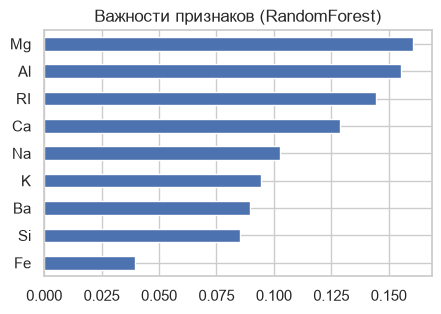

In [5]:
from sklearn.feature_selection import RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
X, y = scaled[FEATURES], scaled["Type"]
f_filter  = X.columns[SelectKBest(f_classif, k=6).fit(X, y).get_support()].tolist()
f_wrapper = X.columns[RFE(LogisticRegression(max_iter=2000), n_features_to_select=6).fit(X, y).get_support()].tolist()
rf = RandomForestClassifier(n_estimators=300, random_state=42)
f_embed   = X.columns[SelectFromModel(rf, threshold="median").fit(X, y).get_support()].tolist()
tab = pd.DataFrame({"Фильтр (F-тест, k=6)": [f in f_filter for f in FEATURES],
                    "Обёртка (RFE + LogReg, 6)": [f in f_wrapper for f in FEATURES],
                    "Встроенный (RandomForest, median)": [f in f_embed for f in FEATURES]}, index=FEATURES)
tab["голосов"] = tab.sum(axis=1)
display(tab.astype(int))
print("Число отобранных:", {c: int(tab[c].sum()) for c in tab.columns[:3]})
rf_imp = pd.Series(rf.fit(X, y).feature_importances_, index=FEATURES).sort_values()
rf_imp.plot.barh(figsize=(5, 3.2), title="Важности признаков (RandomForest)"); plt.show()

In [6]:
selected, SEL = select_glass(scaled)
print("Итоговый набор (признаки, набравшие >= 2 голосов из 3):", SEL)
print("Размерность: до отбора", scaled.shape, "-> после", selected.shape)
selected.to_csv("glass_selected.csv", index=False)
# сравнение качества «до/после» (кросс-валидация, логистическая регрессия и случайный лес)
from sklearn.model_selection import cross_val_score, StratifiedKFold
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows = []
for name, mdl in [("LogReg", LogisticRegression(max_iter=3000)), ("RandomForest", RandomForestClassifier(200, random_state=42))]:
    rows.append([name, cross_val_score(mdl, scaled[FEATURES], y, cv=cv).mean(), cross_val_score(mdl, selected[SEL], y, cv=cv).mean()])
display(pd.DataFrame(rows, columns=["модель", f"все признаки ({len(FEATURES)})", f"после отбора ({len(SEL)})"]).round(3))

Итоговый набор (признаки, набравшие >= 2 голосов из 3): ['Na', 'Mg', 'Al', 'K', 'Ca', 'Ba']
Размерность: до отбора (213, 10) -> после (213, 7)


,модель,все признаки (9),после отбора (6)
0,LogReg,0.652,0.620
1,RandomForest,0.765,0.747


### Итоговый текст

Отбор признаков в сквозном пайплайне выполняется после очистки и масштабирования и перед обучением моделей: он сокращает пространство признаков, не меняя значений в оставшихся столбцах. В работе применены три разных подхода: фильтр (F-тест ANOVA, учитывающий связь признака с классом), обёртка (рекурсивное исключение признаков RFE с логистической регрессией) и встроенный метод (важности признаков случайного леса). Каждый метод имеет свои слепые зоны: фильтр оценивает признаки по одному, RFE зависит от линейной модели, а важности леса смещены в пользу признаков с большим числом уникальных значений. Поэтому итоговый набор формировался голосованием: в выборку включались признаки, выбранные хотя бы двумя методами из трёх. Такой подход устойчив к недостаткам отдельных методов и не требует подбора порога вручную. Параметр k = 6 выбран, чтобы убрать примерно треть признаков, не потеряв информативные оксиды. Сравнение «до/после» показало, что при сокращении числа признаков с 9 до 6 точность в кросс-валидации снизилась лишь незначительно (логистическая регрессия: 0.652 → 0.620, случайный лес: 0.765 → 0.747), то есть основная информация сохранена. Показательно, что голосование оставило K и Ca, которые отбросил простой корреляционный фильтр из уровня 1: это подтверждает риск удаления признаков по одной линейной корреляции. Итоговая выборка (Na, Mg, Al, K, Ca, Ba) оптимальна по размерности: исключены RI, Si и Fe, которые поддержал не более чем один метод, а сохранены оксиды, несущие информацию о разных сортах (Mg и Al — окна, Ba — фары, K — контейнеры, Ca и Na — посуда и прочие). Она остаётся масштабированной, без пропусков и дубликатов, содержит целевую переменную Type и сохранена в `glass_selected.csv`. Эта выборка используется в ЛР 9–12 для обучения и сравнения моделей классификации.